In [2]:
# 1. IMPORT LIBRARIES



import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd


In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator #data augmentation

In [4]:
imgage_size=(150,150)
batch_size=32

In [5]:
train_datagen=ImageDataGenerator(rescale=1/255,   
                                 shear_range=0.2, #check more option
                                 
                                 )

test_datagen=ImageDataGenerator(rescale=1/255,
                                 shear_range=0.2, #check more option
                                 )

In [6]:
training_set=train_datagen.flow_from_directory('D:\Artificial Intelligence\Deep Learning\Data\Icream_pizza\Train',
                                               target_size=imgage_size,
                                               batch_size=batch_size,
                                               class_mode='binary')


test_set=train_datagen.flow_from_directory('D:\Artificial Intelligence\Deep Learning\Data\Icream_pizza\Test',
                                               target_size=imgage_size,
                                               batch_size=batch_size,
                                               class_mode='binary')

Found 718 images belonging to 2 classes.
Found 106 images belonging to 2 classes.


<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:7: SyntaxWarning: invalid escape sequence '\A'
<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:7: SyntaxWarning: invalid escape sequence '\A'
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_17936\1483675701.py:1: SyntaxWarning: invalid escape sequence '\A'
  training_set=train_datagen.flow_from_directory('D:\Artificial Intelligence\Deep Learning\Data\Icream_pizza\Train',
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_17936\1483675701.py:7: SyntaxWarning: invalid escape sequence '\A'
  test_set=train_datagen.flow_from_directory('D:\Artificial Intelligence\Deep Learning\Data\Icream_pizza\Test',


In [7]:

#build model 
model=keras.Sequential(
    [
        
        keras.layers.Conv2D(32,(3,3), activation='relu',input_shape=(150,150,3)),     
     
        keras.layers.MaxPooling2D((3,3)),     
        keras.layers.Conv2D(32,(3,3), activation='relu'),     
        keras.layers.MaxPooling2D((3,3)),     
        keras.layers.Conv2D(32,(3,3), activation='relu'),     
        keras.layers.Flatten(),     
        keras.layers.Dense(512, activation='relu',),     
        keras.layers.Dense(1, activation='sigmoid'),     
     
     ]
)

c:\Users\HASEEB\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.compile(loss='binary_crossentropy',
              optimizer='adam',metrics=['accuracy']


)


history = model.fit(
    training_set,
    epochs=10,
    validation_data=test_set
)

Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 27s 956ms/step - accuracy: 0.6393 - loss: 0.7379 - val_accuracy: 0.8113 - val_loss: 0.5045
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 17s 737ms/step - accuracy: 0.7855 - loss: 0.4530 - val_accuracy: 0.8302 - val_loss: 0.3991
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 18s 780ms/step - accuracy: 0.8482 - loss: 0.3710 - val_accuracy: 0.8774 - val_loss: 0.3044
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 19s 812ms/step - accuracy: 0.8621 - loss: 0.3270 - val_accuracy: 0.8962 - val_loss: 0.2664
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 18s 806ms/step - accuracy: 0.8510 - loss: 0.3167 - val_accuracy: 0.8585 - val_loss: 0.2693
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 17s 723ms/step - accuracy: 0.9053 - loss: 0.2427 - val_accuracy: 0.9340 - val_loss: 0.1570
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 16s 705ms/step - accuracy: 0.9178 - loss: 0.2048 - val_accuracy: 0.9623 - val_loss: 0.1337
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 620ms/step - accuracy: 0.9095 - loss: 0.2114 - val_accu

In [9]:
test_loss, test_acc = model.evaluate(test_set)

print('Test Loss:', test_loss)
print('Test Accuracy:', test_acc)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 320ms/step - accuracy: 0.9623 - loss: 0.0977
Test Loss: 0.0977291464805603
Test Accuracy: 0.9622641801834106


In [10]:

y_pred = model.predict(test_set)
import numpy as np

y_pred = np.argmax(y_pred, axis=1)
y_true = test_set.classes

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 323ms/step


In [11]:
y_true

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

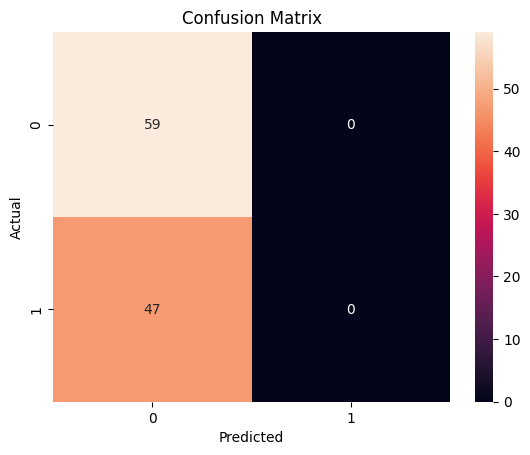

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred))





              precision    recall  f1-score   support

           0       0.56      1.00      0.72        59
           1       0.00      0.00      0.00        47

    accuracy                           0.56       106
   macro avg       0.28      0.50      0.36       106
weighted avg       0.31      0.56      0.40       106



c:\Users\HASEEB\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HASEEB\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HASEEB\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

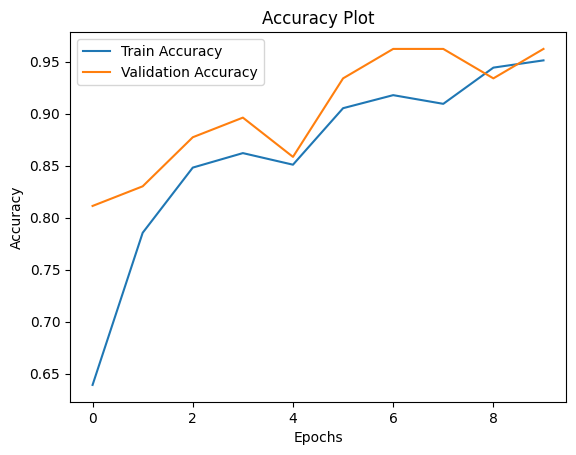

In [14]:
plt.figure()

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Accuracy Plot')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [18]:
model.save('Icream_pizza.model.h5')
print('Model Saved Successfully!')


Model Saved Successfully!


In [20]:
from tensorflow import keras 
loaded_model = keras.models.load_model("D:\Artificial Intelligence\Deep Learning\Models\Icream_pizza.model.h5")
print("Model loaded Successfully!")        

<>:2: SyntaxWarning: invalid escape sequence '\A'
<>:2: SyntaxWarning: invalid escape sequence '\A'
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_17936\1304827230.py:2: SyntaxWarning: invalid escape sequence '\A'
  loaded_model = keras.models.load_model("D:\Artificial Intelligence\Deep Learning\Models\Icream_pizza.model.h5")


Model loaded Successfully!
